# Assignment 3 - Subword Tokenization on IndicCorp v2 (Gujarati)

**U23AI051**

Corpus: [`ai4bharat/IndicCorpV2`](https://huggingface.co/datasets/ai4bharat/IndicCorpV2), split `guj_Gujr` -> `data/gu.txt`.
Each line of that file is a **paragraph**, so the first job is sentence tokenization.

Tasks:

1. Train / dev / test splits. Dev and test are 1000 sentences each, **chosen so they span the whole
   length range** rather than clustering at the modal sentence length. Everything else is training data.
2. **BPE** and **WordPiece**, implemented from scratch and then run at scale, used to tokenize dev and test.
3. Effect of **training-data size**: 100k / 300k / 500k / 1M sentences.
4. Effect of **vocabulary size**: 20k / 30k / 50k.

Sections 3 and 4 of the task sheet are run as one full 4 x 3 x 2 = 24-tokenizer grid, so each effect
can be read while the other variable is held fixed.

**On the implementation.** Sections 4-5 implement BPE and WordPiece from scratch (merge loop, pair
scoring, greedy longest-match encoding) and validate them. The 24-config grid in section 6 uses the
Rust `tokenizers` library, because 24 trainings up to 1M sentences x 50k vocab is hours in pure
Python and minutes in Rust. Section 5 shows the two agree.

## 0. Settings

In [35]:
import os, re, io, json, time, random
from collections import Counter, defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

LANG        = "gu"                                  # Gujarati, split guj_Gujr
DEV_SIZE    = 1_000
TEST_SIZE   = 1_000
TRAIN_SIZES = [100_000, 300_000, 500_000, 1_000_000]
VOCAB_SIZES = [20_000, 30_000, 50_000]
ALGORITHMS  = ["BPE", "WordPiece"]

N_SENTENCES = max(TRAIN_SIZES) + DEV_SIZE + TEST_SIZE     # how many to harvest from the corpus

DEMO_N      = 3_000      # sentences used for the from-scratch demonstration (section 5)
DEMO_VOCAB  = 500

SPECIALS  = ["[UNK]", "[PAD]"]
EOW       = "</w>"       # BPE end-of-word marker
SEED      = 42

WORK = "/kaggle/working" if os.path.isdir("/kaggle/working") else "."
os.makedirs(f"{WORK}/tokenizers", exist_ok=True)

pd.set_option("display.width", 160)
print(f"working directory: {WORK}")

working directory: /kaggle/working


In [36]:
try:
    import tokenizers
except ImportError:
    !pip install -q tokenizers
    import tokenizers

import requests
print("tokenizers", tokenizers.__version__)

tokenizers 0.22.2


## 1. Corpus: stream and sentence-tokenize

`data/gu.txt` is several GB and we only need ~1M sentences, so we stream it over HTTP and stop as
soon as we have enough - no full download.

**Sentence tokenization.** Gujarati web text ends sentences with the danda, the double danda, or
western `.` `!` `?`. We split on any of those followed by whitespace.

A sentence is kept only if it

* contains at least one Gujarati character (drops the English / URL / markup lines IndicCorp keeps),
* has between 3 and 150 whitespace tokens (drops fragments and unsplit run-on blobs), and
* has not been seen before (IndicCorp is web-scraped; boilerplate lines repeat thousands of times,
  and duplicates would leak between train and test).

In [37]:
GUJARATI      = re.compile("[઀-૿]")               # Unicode block: Gujarati
SENT_BOUNDARY = re.compile("(?<=[।॥.!?])\\s+")    # danda, double danda, . ! ?

MIN_WORDS, MAX_WORDS = 3, 150


def sentences(paragraph):
    """Split one IndicCorp paragraph into clean Gujarati sentences."""
    for sentence in SENT_BOUNDARY.split(paragraph.strip()):
        sentence = " ".join(sentence.split())               # collapse all whitespace runs
        if MIN_WORDS <= len(sentence.split()) <= MAX_WORDS and GUJARATI.search(sentence):
            yield sentence


# quick check: two Gujarati sentences plus a URL that must be dropped
demo_paragraph = ("તેમણે કહું કે "
                  "આ કામ થશે। "
                  "બાકીનું કામ "
                  "ચાલુ છે. http://example.com")
for s in sentences(demo_paragraph):
    print(repr(s))

'તેમણે કહું કે આ કામ થશે।'
'બાકીનું કામ ચાલુ છે.'


In [38]:
URL      = f"https://huggingface.co/datasets/ai4bharat/IndicCorpV2/resolve/main/data/{LANG}.txt"
RAW_PATH = f"{WORK}/{LANG}_sentences.txt"

if os.path.exists(RAW_PATH):
    corpus = io.open(RAW_PATH, encoding="utf-8").read().splitlines()
    print(f"loaded {len(corpus):,} cached sentences from {RAW_PATH}")
else:
    corpus, seen = [], set()
    paragraphs, start = 0, time.time()

    with requests.get(URL, stream=True, timeout=120) as response:
        if response.status_code in (401, 403):
            raise SystemExit("IndicCorpV2 needs authentication - run "
                             "`from huggingface_hub import login; login()` and re-run this cell.")
        response.raise_for_status()
        response.encoding = "utf-8"

        for line in response.iter_lines(decode_unicode=True):
            if not line:
                continue
            paragraphs += 1
            for sentence in sentences(line):
                key = hash(sentence)          # ponytail: hashes, not strings - 1M strings is ~200MB
                if key not in seen:
                    seen.add(key)
                    corpus.append(sentence)
            if len(corpus) >= N_SENTENCES:
                break
            if paragraphs % 100_000 == 0:
                print(f"  {paragraphs:>9,} paragraphs -> {len(corpus):>9,} sentences "
                      f"({time.time() - start:.0f}s)")

    corpus = corpus[:N_SENTENCES]
    io.open(RAW_PATH, "w", encoding="utf-8").write("\n".join(corpus))
    print(f"\n{paragraphs:,} paragraphs -> {len(corpus):,} sentences in {time.time() - start:.0f}s")
    print(f"saved to {RAW_PATH}")

loaded 1,002,000 cached sentences from /kaggle/working/gu_sentences.txt


In [39]:
word_counts = np.array([len(s.split()) for s in corpus])
char_counts = np.array([len(s) for s in corpus])

print(f"sentences        {len(corpus):,}")
print(f"words            {word_counts.sum():,}")
print(f"characters       {char_counts.sum():,}")
print(f"words / sentence {word_counts.mean():.1f}  (median {np.median(word_counts):.0f}, "
      f"p95 {np.percentile(word_counts, 95):.0f}, max {word_counts.max()})")
print(f"unique words     {len({w for s in corpus[:200_000] for w in s.split()}):,} "
      f"(in the first 200k sentences)")

for s in corpus[:3]:
    print("\n" + s)

sentences        1,002,000
words            15,147,366
characters       89,896,665
words / sentence 15.1  (median 13, p95 33, max 150)
unique words     275,221 (in the first 200k sentences)

આ વીડિયો જુઓ: ઊંઝા માર્કેટયાર્ડ આજથી 25 જુલાઈ સુધી બંધ

મિથેનોલ આવ્યો ક્યાંથી?

આખરે ત્રણ રાજ્યોમાં મળેલ હાર પર કોંગ્રેસ અધ્યક્ષ રાહુલ ગાંધી દ્વારા પ્રથમ પ્રતિક્રિયા આપવામાં આવી છે.


## 2. Splits

Dev and test are 1000 sentences each; everything else is training data.

**Length-aware selection.** Sampling 1000 sentences uniformly at random would reproduce the corpus
length distribution, which is sharply peaked - most of dev/test would land at roughly the modal
length and the tokenizers would never be measured on very short or very long input. Instead:

1. sort the shuffled corpus by word count,
2. cut it into **10 equal-sized deciles** (decile 1 = shortest 10%, decile 10 = longest 10%),
3. take **100 dev + 100 test sentences from each decile**.

That gives equal mass per decile: every length band from the shortest to the longest is represented
by exactly 100 sentences in each set, so the evaluation sets are not made of similar-length sentences.

Training subsets are **nested prefixes** of the remaining pool (100k is contained in 300k, and so
on), so the size comparison in section 7 varies only the amount of data, not which data.

In [40]:
rng = random.Random(SEED)

pool = corpus[:]
rng.shuffle(pool)

lengths = np.array([len(s.split()) for s in pool])
deciles = np.array_split(np.argsort(lengths, kind="stable"), 10)

per_decile_dev, per_decile_test = DEV_SIZE // 10, TEST_SIZE // 10

dev_idx, test_idx, rows = [], [], []
for number, decile in enumerate(deciles, start=1):
    picked = rng.sample(list(decile), per_decile_dev + per_decile_test)
    dev_idx  += picked[:per_decile_dev]
    test_idx += picked[per_decile_dev:]
    rows.append({"decile": number,
                 "min words": int(lengths[decile].min()),
                 "median":    int(np.median(lengths[decile])),
                 "max words": int(lengths[decile].max()),
                 "dev": per_decile_dev, "test": per_decile_test})

held_out  = set(dev_idx) | set(test_idx)
dev_set   = [pool[i] for i in dev_idx]
test_set  = [pool[i] for i in test_idx]
train_all = [s for i, s in enumerate(pool) if i not in held_out]

TRAIN_SIZES = [n for n in TRAIN_SIZES if n <= len(train_all)]      # guard if the corpus was short
print(f"train {len(train_all):,}   dev {len(dev_set):,}   test {len(test_set):,}")
print(f"training sizes to evaluate: {TRAIN_SIZES}\n")
pd.DataFrame(rows)

train 1,000,000   dev 1,000   test 1,000
training sizes to evaluate: [100000, 300000, 500000, 1000000]



,decile,min words,median,max words,dev,test
0,1,3,5,6,100,100
1,2,6,7,8,100,100
2,3,8,9,9,100,100
3,4,9,10,11,100,100
4,5,11,12,13,100,100
5,6,13,14,15,100,100
6,7,15,16,17,100,100
7,8,17,19,20,100,100
8,9,20,23,26,100,100
9,10,26,33,150,100,100


In [41]:
def length_summary(name, part):
    words = [len(s.split()) for s in part]
    return {"split": name, "sentences": len(part),
            "mean words": np.mean(words), "std words": np.std(words),
            "min": min(words), "p25": np.percentile(words, 25),
            "p75": np.percentile(words, 75), "max": max(words)}


print("Dev/test cover the same range as train but with a much larger spread - that is the point.\n")
pd.DataFrame([length_summary("train", train_all),
              length_summary("dev", dev_set),
              length_summary("test", test_set)]).round(1)

Dev/test cover the same range as train but with a much larger spread - that is the point.



,split,sentences,mean words,std words,min,p25,p75,max
0,train,1000000,15.1,10.2,3,9.0,19.0,150
1,dev,1000,14.9,9.1,3,9.0,18.0,76
2,test,1000,15.0,9.4,3,9.0,19.0,77


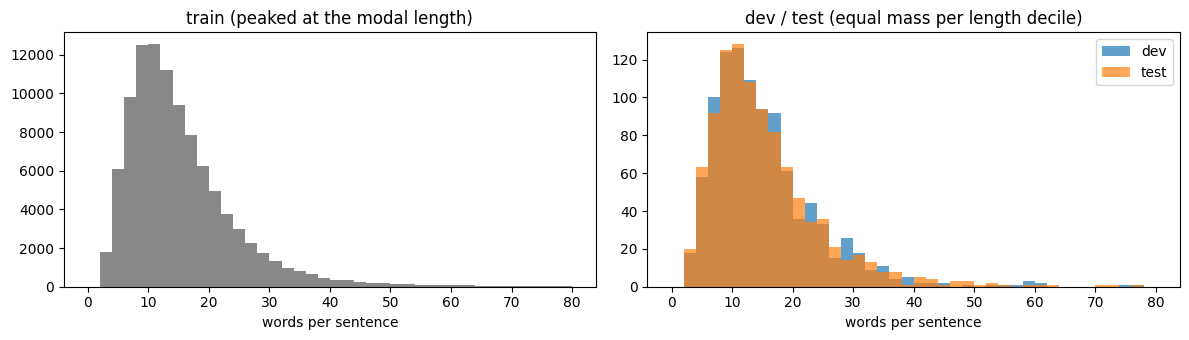

In [42]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.5))
bins = np.arange(0, 81, 2)

axes[0].hist([len(s.split()) for s in train_all[:100_000]], bins=bins, color="#888")
axes[0].set_title("train (peaked at the modal length)")
axes[1].hist([len(s.split()) for s in dev_set], bins=bins, alpha=.7, label="dev")
axes[1].hist([len(s.split()) for s in test_set], bins=bins, alpha=.7, label="test")
axes[1].set_title("dev / test (equal mass per length decile)")
axes[1].legend()
for ax in axes:
    ax.set_xlabel("words per sentence")
plt.tight_layout(); plt.show()

In [43]:
for name, part in [("train", train_all), ("dev", dev_set), ("test", test_set)]:
    io.open(f"{WORK}/{name}.txt", "w", encoding="utf-8").write("\n".join(part))
print("splits written to", WORK)

splits written to /kaggle/working


## 3. What the two algorithms actually do

Both start from characters and grow a vocabulary of subwords by repeatedly merging a pair of adjacent
symbols. They differ in **which pair they pick** and in **how a word is later segmented**.

|                | BPE                                     | WordPiece                                                      |
|----------------|-----------------------------------------|----------------------------------------------------------------|
| pair score     | raw frequency `f(a, b)`                 | `f(a, b) / (f(a) * f(b))`                                      |
| effect         | merges whatever is common               | merges what co-occurs *more than chance* - penalises pairs whose halves are already frequent alone |
| word boundary  | `</w>` appended to the last symbol      | `##` prefixed to every non-initial symbol                      |
| encoding       | replay the merge list in training order | greedy longest-match-first against the final vocabulary        |
| unknown char   | stays as a character token              | the whole word becomes `[UNK]`                                 |

The likelihood-style score is why WordPiece tends to keep morphemes intact where BPE will happily
glue a frequent suffix onto a frequent stem.

## 4. From-scratch implementations

Written against word **type frequencies** rather than the raw token stream - every identical word is
processed once, weighted by its count. That is the standard formulation and it is what makes the
merge loop tractable at all.

The BPE trainer maintains the pair-frequency table and a `pair -> words containing it` index
**incrementally**: after a merge only the words that contained that pair change, so each merge costs
O(affected words) instead of a full re-scan of the vocabulary.

WordPiece needs the current frequency of every *token* as well as every pair, so it re-scans each
round - slower, and the reason the demo below is small.

**One thing the textbook statement of WordPiece leaves out.** The score `f(a,b) / (f(a) * f(b))` is
maximised at 1.0 by any pair whose two halves occur nowhere else - a typo, a stray Latin fragment, a
one-off. Scored literally, the entire vocabulary goes to hapaxes and the tokenizer ends up splitting
real Gujarati into single characters (measured: 5.0 tokens per word instead of 3.7). Production
WordPiece applies a count threshold; so does this implementation, defaulting to one occurrence per
500 word tokens.

In [44]:
def word_frequencies(sentences_):
    """Word type -> count. Whitespace tokenization, as in the earlier assignments."""
    counts = Counter()
    for sentence in sentences_:
        counts.update(sentence.split())
    return counts


def apply_merge(symbols, pair, merged):
    """Replace every adjacent occurrence of `pair` in a symbol tuple with `merged`."""
    out, i = [], 0
    while i < len(symbols):
        if i + 1 < len(symbols) and symbols[i] == pair[0] and symbols[i + 1] == pair[1]:
            out.append(merged)
            i += 2
        else:
            out.append(symbols[i])
            i += 1
    return tuple(out)

In [45]:
class BPE:
    """Byte-pair encoding at the character level, with an end-of-word marker."""

    def train(self, word_freqs, vocab_size, verbose=False):
        splits = {word: tuple(word) + (EOW,) for word in word_freqs}

        pair_freq = Counter()                       # pair -> total frequency
        holders   = defaultdict(set)                # pair -> words currently containing it
        for word, symbols in splits.items():
            frequency = word_freqs[word]
            for pair in zip(symbols, symbols[1:]):
                pair_freq[pair] += frequency
                holders[pair].add(word)

        self.vocab  = sorted({symbol for s in splits.values() for symbol in s})
        self.merges = []

        while len(self.vocab) < vocab_size and pair_freq:
            best = max(pair_freq, key=lambda p: (pair_freq[p], p))   # ties broken deterministically
            if pair_freq[best] < 2:
                break
            merged = best[0] + best[1]
            self.merges.append(best)
            self.vocab.append(merged)

            for word in list(holders[best]):                         # only affected words change
                symbols   = splits[word]
                frequency = word_freqs[word]
                for pair in zip(symbols, symbols[1:]):
                    pair_freq[pair] -= frequency
                    if pair_freq[pair] <= 0:
                        del pair_freq[pair]
                    holders[pair].discard(word)

                symbols = apply_merge(symbols, best, merged)
                splits[word] = symbols
                for pair in zip(symbols, symbols[1:]):
                    pair_freq[pair] += frequency
                    holders[pair].add(word)

            if verbose and len(self.merges) % 100 == 0:
                print(f"  {len(self.merges):>5} merges, vocab {len(self.vocab):>5}, "
                      f"last {''.join(best)!r}")

        self.rank  = {pair: i for i, pair in enumerate(self.merges)}
        self.cache = {}
        return self

    def encode_word(self, word):
        if word in self.cache:
            return self.cache[word]

        symbols = tuple(word) + (EOW,)
        while len(symbols) > 1:
            ranked = [self.rank[p] for p in zip(symbols, symbols[1:]) if p in self.rank]
            if not ranked:
                break
            pair = self.merges[min(ranked)]              # earliest merge first, as during training
            symbols = apply_merge(symbols, pair, pair[0] + pair[1])

        self.cache[word] = list(symbols)
        return self.cache[word]

    def encode(self, sentence):
        return [t for word in sentence.split() for t in self.encode_word(word)]

    def decode(self, tokens):
        return "".join(tokens).replace(EOW, " ").strip()

In [46]:
class WordPiece:
    """WordPiece: likelihood-scored merges, greedy longest-match encoding."""

    def train(self, word_freqs, vocab_size, min_frequency=None, verbose=False):
        # The score is maximised by a pair whose halves occur nowhere else: 1 / (1 * 1) = 1.
        # Without a floor the whole vocabulary goes to one-off typos and stray Latin fragments,
        # so only pairs seen at least `min_frequency` times are eligible.
        if min_frequency is None:
            min_frequency = max(2, sum(word_freqs.values()) // 500)

        splits = {word: [word[0]] + ["##" + c for c in word[1:]] for word in word_freqs if word}
        self.vocab = sorted({t for s in splits.values() for t in s}) + ["[UNK]"]

        while len(self.vocab) < vocab_size:
            pair_freq, token_freq = Counter(), Counter()
            for word, symbols in splits.items():
                frequency = word_freqs[word]
                for token in symbols:
                    token_freq[token] += frequency
                for pair in zip(symbols, symbols[1:]):
                    pair_freq[pair] += frequency

            eligible = {p: c for p, c in pair_freq.items() if c >= min_frequency}
            if not eligible:
                break

            best = max(eligible,
                       key=lambda p: (eligible[p] / (token_freq[p[0]] * token_freq[p[1]]), p))
            merged = best[0] + best[1][2:]                   # the right half always carries "##"
            if merged in self.vocab:                         # already built by another route
                del pair_freq[best]
                continue
            self.vocab.append(merged)

            for word, symbols in splits.items():
                splits[word] = list(apply_merge(tuple(symbols), best, merged))

            if verbose and len(self.vocab) % 100 == 0:
                print(f"  vocab {len(self.vocab):>5}, last {merged!r}")

        self.vocab_set = set(self.vocab)
        self.cache = {}
        return self

    def encode_word(self, word):
        if word in self.cache:
            return self.cache[word]

        tokens, start = [], 0
        while start < len(word):
            end = len(word)
            while start < end:
                candidate = word[start:end] if start == 0 else "##" + word[start:end]
                if candidate in self.vocab_set:
                    break
                end -= 1
            if start == end:                                 # no prefix of the rest is in the vocab
                tokens = ["[UNK]"]
                break
            tokens.append(candidate)
            start = end

        self.cache[word] = tokens
        return tokens

    def encode(self, sentence):
        return [t for word in sentence.split() for t in self.encode_word(word)]

    def decode(self, tokens):
        return " ".join(tokens).replace(" ##", "")

### 4.1 Self-check on a toy corpus

The classic four-word example. Everything below must hold or the implementations are wrong.

In [ ]:
toy = Counter({"low": 5, "lower": 2, "newest": 6, "widest": 3})

bpe_toy = BPE().train(toy, vocab_size=30)
wp_toy  = WordPiece().train(toy, vocab_size=30)

# 1. lossless round-trip, including on words never seen during training
for word in ["newest", "lowest", "wider"]:
    assert bpe_toy.decode(bpe_toy.encode_word(word)) == word, word
    assert wp_toy.decode(wp_toy.encode_word(word)) == word, word

# 2. merging actually shortened things (6 characters -> fewer symbols)
assert len(bpe_toy.encode_word("newest")) < 7
assert len(wp_toy.encode_word("newest")) < 6

# 3. "n" never occurs word-internally in the toy corpus, so "##n" is not in the WordPiece
#    vocabulary and the entire word is lost ...
assert wp_toy.encode_word("widen") == ["[UNK]"]

# 4. ... where BPE degrades to characters and still round-trips
assert bpe_toy.decode(bpe_toy.encode_word("widen")) == "widen"

# 5. sentence-level round-trip
assert bpe_toy.decode(bpe_toy.encode("low lower newest")) == "low lower newest"

print("all checks passed\n")
print("BPE first merges   :", ["".join(m) for m in bpe_toy.merges[:6]])
print("newest -> BPE      :", bpe_toy.encode_word("newest"))    
print("newest -> WordPiece:", wp_toy.encode_word("newest"))
print("widen  -> BPE      :", bpe_toy.encode_word("widen"))
print("widen  -> WordPiece:", wp_toy.encode_word("widen"), " (no '##n' in the vocabulary)")

all checks passed

BPE first merges   : ['t</w>', 'st</w>', 'est</w>', 'ow', 'low', 'west</w>']
newest -> BPE      : ['newest</w>']
newest -> WordPiece: ['newest']
widen  -> BPE      : ['wid', 'e', 'n', '</w>']
widen  -> WordPiece: ['[UNK]']  (no '##n' in the vocabulary)


## 5. From-scratch vs. the Rust library

Same 3000 Gujarati sentences, same target vocabulary, both implementations. The point is to confirm
the from-scratch code produces the same kind of vocabulary as the reference implementation - not a
byte-identical one, since `tokenizers` applies NFC normalization and a regex pre-tokenizer that
splits punctuation off words, which plain whitespace splitting does not.

In [48]:
demo_sentences = train_all[:DEMO_N]
demo_freqs     = word_frequencies(demo_sentences)
print(f"{len(demo_sentences):,} sentences, {len(demo_freqs):,} word types, "
      f"{sum(demo_freqs.values()):,} word tokens\n")

start = time.time()
bpe_scratch = BPE().train(demo_freqs, DEMO_VOCAB, verbose=True)
print(f"BPE from scratch      : vocab {len(bpe_scratch.vocab):,}, "
      f"{len(bpe_scratch.merges):,} merges, {time.time() - start:.1f}s\n")

start = time.time()
wp_scratch = WordPiece().train(demo_freqs, DEMO_VOCAB, verbose=True)
print(f"WordPiece from scratch: vocab {len(wp_scratch.vocab):,}, {time.time() - start:.1f}s")

3,000 sentences, 15,946 word types, 44,805 word tokens

    100 merges, vocab   277, last 'એક</w>'
    200 merges, vocab   377, last 'વાની</w>'
    300 merges, vocab   477, last 'દુ'
BPE from scratch      : vocab 500, 323 merges, 1.6s

  vocab   300, last 'રહ'
  vocab   400, last '##સ્ટ'
  vocab   500, last 'પોલીસ'
WordPiece from scratch: vocab 500, 22.0s


In [49]:
from tokenizers import Tokenizer, models, trainers, pre_tokenizers, decoders, normalizers


def train_hf(algorithm, sentences_, vocab_size):
    """Train a `tokenizers` BPE or WordPiece model on an iterable of sentences."""
    if algorithm == "BPE":
        tokenizer = Tokenizer(models.BPE(unk_token="[UNK]", end_of_word_suffix=EOW))
        trainer   = trainers.BpeTrainer(vocab_size=vocab_size, special_tokens=SPECIALS,
                                        end_of_word_suffix=EOW, show_progress=False)
        tokenizer.decoder = decoders.BPEDecoder(suffix=EOW)
    else:
        tokenizer = Tokenizer(models.WordPiece(unk_token="[UNK]", max_input_chars_per_word=150))
        trainer   = trainers.WordPieceTrainer(vocab_size=vocab_size, special_tokens=SPECIALS,
                                              show_progress=False)
        tokenizer.decoder = decoders.WordPiece()

    tokenizer.normalizer    = normalizers.NFC()
    tokenizer.pre_tokenizer = pre_tokenizers.Whitespace()
    tokenizer.train_from_iterator(sentences_, trainer)
    return tokenizer


bpe_hf = train_hf("BPE",       demo_sentences, DEMO_VOCAB)
wp_hf  = train_hf("WordPiece", demo_sentences, DEMO_VOCAB)
print("reference tokenizers trained")

reference tokenizers trained


In [50]:
def tokens_per_word_scratch(model, sentences_):
    tokens = sum(len(model.encode(s)) for s in sentences_)
    words  = sum(len(s.split())       for s in sentences_)
    return tokens / words


def tokens_per_word_hf(tokenizer, sentences_):
    encodings = tokenizer.encode_batch(sentences_)
    tokens = sum(len(e.ids)     for e in encodings)
    words  = sum(len(s.split()) for s in sentences_)
    return tokens / words


comparison = []
for name, scratch, reference in [("BPE", bpe_scratch, bpe_hf), ("WordPiece", wp_scratch, wp_hf)]:
    scratch_vocab   = {t.replace(EOW, "") for t in scratch.vocab}
    reference_vocab = {t.replace(EOW, "") for t in reference.get_vocab()}
    overlap = len(scratch_vocab & reference_vocab) / len(scratch_vocab | reference_vocab)

    comparison.append({
        "algorithm":                name,
        "vocab (scratch)":          len(scratch.vocab),
        "vocab (tokenizers)":       reference.get_vocab_size(),
        "vocab Jaccard overlap":    round(overlap, 3),
        "tokens/word (scratch)":    round(tokens_per_word_scratch(scratch, dev_set), 3),
        "tokens/word (tokenizers)": round(tokens_per_word_hf(reference, dev_set), 3),
    })

pd.DataFrame(comparison)

,algorithm,vocab (scratch),vocab (tokenizers),vocab Jaccard overlap,tokens/word (scratch),tokens/word (tokenizers)
0,BPE,500,500,0.741,3.072,3.355
1,WordPiece,500,500,0.577,3.854,3.326


In [51]:
example = dev_set[7]
print(example, "\n")
print("BPE       scratch    :", " ".join(bpe_scratch.encode(example)))
print("BPE       tokenizers :", " ".join(bpe_hf.encode(example).tokens))
print()
print("WordPiece scratch    :", " ".join(wp_scratch.encode(example)))
print("WordPiece tokenizers :", " ".join(wp_hf.encode(example).tokens))
print()
print("BPE round-trip ok    :", bpe_scratch.decode(bpe_scratch.encode(example)) == example)

૧૦૦-૧૦૨ પ્રાઇસ બેન્ડ 

BPE       scratch    : ૧ ૦ ૦ - ૧ ૦ ૨ </w> પ્ર ા ઇ સ</w> બે ન્ ડ</w>
BPE       tokenizers : ૧ ૦ ૦</w> -</w> ૧ ૦ ૨</w> પ્ર ા ઇ સ</w> બે ન્ ડ</w>

WordPiece scratch    : ૧ ##૦ ##૦ ##- ##૧ ##૦ ##૨ પ્ર ##ા ##ઇ ##સ બ ##ે ##ન્ડ
WordPiece tokenizers : ૧ ##૦ ##૦ - ૧ ##૦ ##૨ પ્ર ##ાઇ ##સ બે ##ન્ડ

BPE round-trip ok    : True


**Reading that table.** BPE lines up closely - most of the vocabulary is shared, and the example
below is segmented identically. Most of what does differ is punctuation: `tokenizers` splits a full
stop into its own pre-token, so a word followed by one is two words there and a single word here,
which shifts both the vocabulary and the per-word counts.

WordPiece diverges more. Both implementations use the likelihood score, but they break ties and
apply their frequency thresholds differently, and at a 500-token vocabulary every early merge
decision compounds - the from-scratch version segments more finely as a result. The gap narrows at
realistic vocabulary sizes, where the first few hundred merges matter proportionally less.

Neither difference is an error: both are lossless, both produce linguistically sensible Gujarati
merges (locative `##માં`, the participial `##ેલ`), and both show the mechanism the assignment is
about. The 24-configuration grid below uses the library so that it finishes in minutes rather than
hours.

## 6. The 4 x 3 x 2 grid

Four training sizes, three vocabulary sizes, two algorithms. Each tokenizer is evaluated on dev and
test with five measures:

| measure | meaning |
|---|---|
| `tokens/sentence` | sequence length a downstream model would see |
| `tokens/word`     | **fertility** - how many pieces the average word is cut into (1.0 = word-level) |
| `chars/token`     | compression - how much text each vocabulary entry carries |
| `%words unsplit`  | share of words that survive as a single token |
| `UNK rate`        | share of emitted tokens that are `[UNK]` |

`tokens/word` is the headline number: it falls as the tokenizer gets better at covering the language.

In [52]:
def evaluate(tokenizer, sentences_):
    encodings = tokenizer.encode_batch(sentences_)
    unk_id    = tokenizer.token_to_id("[UNK]")

    n_tokens = n_unk = n_words = n_unsplit = 0
    for encoding in encodings:
        n_tokens  += len(encoding.ids)
        n_unk     += encoding.ids.count(unk_id)
        pieces     = Counter(w for w in encoding.word_ids if w is not None)
        n_words   += len(pieces)
        n_unsplit += sum(1 for count in pieces.values() if count == 1)

    n_chars = sum(len(s) for s in sentences_)
    return {
        "tokens/sentence": n_tokens / len(sentences_),
        "tokens/word":     n_tokens / n_words,
        "chars/token":     n_chars / n_tokens,
        "%words unsplit":  100 * n_unsplit / n_words,
        "UNK rate %":      100 * n_unk / n_tokens,
    }

In [53]:
# The long cell. 24 trainings; expect roughly 30-60 minutes on a Kaggle CPU session.
records, trained = [], {}

for algorithm in ALGORITHMS:
    for train_size in TRAIN_SIZES:
        subset = train_all[:train_size]                  # nested prefixes
        for vocab_size in VOCAB_SIZES:
            start = time.time()
            tokenizer = train_hf(algorithm, subset, vocab_size)
            elapsed = time.time() - start

            key = (algorithm, train_size, vocab_size)
            trained[key] = tokenizer
            tokenizer.save(f"{WORK}/tokenizers/{algorithm}_{train_size}_{vocab_size}.json")

            row = {"algorithm": algorithm, "train size": train_size,
                   "vocab target": vocab_size, "vocab actual": tokenizer.get_vocab_size(),
                   "train seconds": round(elapsed, 1)}
            for split_name, split in [("dev", dev_set), ("test", test_set)]:
                for measure, value in evaluate(tokenizer, split).items():
                    row[f"{split_name} {measure}"] = round(value, 4)
            records.append(row)

            print(f"{algorithm:<10} {train_size:>9,} sents  vocab {vocab_size:>6,} -> "
                  f"{tokenizer.get_vocab_size():>6,}   "
                  f"test tokens/word {row['test tokens/word']:.3f}   {elapsed:.0f}s")

results = pd.DataFrame(records)
results.to_csv(f"{WORK}/results.csv", index=False)
print(f"\n{len(results)} configurations, "
      f"{results['train seconds'].sum() / 60:.1f} minutes of training")

BPE          100,000 sents  vocab 20,000 -> 20,000   test tokens/word 1.243   4s
BPE          100,000 sents  vocab 30,000 -> 30,000   test tokens/word 1.185   4s
BPE          100,000 sents  vocab 50,000 -> 50,000   test tokens/word 1.131   4s
BPE          300,000 sents  vocab 20,000 -> 20,000   test tokens/word 1.243   8s
BPE          300,000 sents  vocab 30,000 -> 30,000   test tokens/word 1.181   9s
BPE          300,000 sents  vocab 50,000 -> 50,000   test tokens/word 1.124   9s
BPE          500,000 sents  vocab 20,000 -> 20,000   test tokens/word 1.242   12s
BPE          500,000 sents  vocab 30,000 -> 30,000   test tokens/word 1.180   13s
BPE          500,000 sents  vocab 50,000 -> 50,000   test tokens/word 1.123   13s
BPE        1,000,000 sents  vocab 20,000 -> 20,000   test tokens/word 1.244   22s
BPE        1,000,000 sents  vocab 30,000 -> 30,000   test tokens/word 1.181   23s
BPE        1,000,000 sents  vocab 50,000 -> 50,000   test tokens/word 1.124   24s
WordPiece    100,000 s

In [54]:
results[["algorithm", "train size", "vocab target", "vocab actual",
         "dev tokens/word", "test tokens/word", "test chars/token",
         "test %words unsplit", "test UNK rate %", "train seconds"]]

,algorithm,train size,vocab target,vocab actual,dev tokens/word,test tokens/word,test chars/token,test %words unsplit,test UNK rate %,train seconds
0,BPE,100000,20000,20000,1.2520,1.2433,4.2231,83.0336,0.0048,3.6
1,BPE,100000,30000,30000,1.1937,1.1845,4.4328,86.6126,0.0050,3.8
2,BPE,100000,50000,50000,1.1370,1.1310,4.6421,90.1621,0.0052,4.1
3,BPE,300000,20000,20000,1.2517,1.2428,4.2245,83.0632,0.0048,8.4
4,BPE,300000,30000,30000,1.1896,1.1807,4.4468,86.7842,0.0050,8.6
5,BPE,300000,50000,50000,1.1304,1.1244,4.6695,90.6235,0.0053,8.9
6,BPE,500000,20000,20000,1.2522,1.2423,4.2265,83.0691,0.0000,12.4
7,BPE,500000,30000,30000,1.1886,1.1800,4.4494,86.8966,0.0000,12.9
8,BPE,500000,50000,50000,1.1298,1.1226,4.6769,90.7596,0.0000,13.2
9,BPE,1000000,20000,20000,1.2530,1.2437,4.2215,83.0277,0.0000,22.4


## 7. Task 3 - effect of training-data size

Vocabulary size is held fixed in each column; only the number of training sentences changes.

In [55]:
for measure in ["test tokens/word", "test %words unsplit", "test UNK rate %"]:
    print(f"\n{measure}")
    display(results.pivot_table(index=["algorithm", "train size"],
                                columns="vocab target", values=measure))


test tokens/word


vocab target           20000   30000   50000
algorithm train size                        
BPE       100000      1.2433  1.1845  1.1310
          300000      1.2428  1.1807  1.1244
          500000      1.2423  1.1800  1.1226
          1000000     1.2437  1.1813  1.1241
WordPiece 100000      1.2256  1.1709  1.1232
          300000      1.2256  1.1690  1.1171
          500000      1.2255  1.1687  1.1148
          1000000     1.2254  1.1695  1.1149


test %words unsplit


vocab target            20000    30000    50000
algorithm train size                           
BPE       100000      83.0336  86.6126  90.1621
          300000      83.0632  86.7842  90.6235
          500000      83.0691  86.8966  90.7596
          1000000     83.0277  86.7842  90.6945
WordPiece 100000      83.8263  87.2515  90.4165
          300000      83.8500  87.3462  90.9844
          500000      83.8677  87.4053  91.1204
          1000000     83.8500  87.3699  91.1145


test UNK rate %


vocab target           20000   30000   50000
algorithm train size                        
BPE       100000      0.0048  0.0050  0.0052
          300000      0.0048  0.0050  0.0053
          500000      0.0000  0.0000  0.0000
          1000000     0.0000  0.0000  0.0000
WordPiece 100000      0.0097  0.0101  0.0105
          300000      0.0097  0.0101  0.0106
          500000      0.0048  0.0051  0.0053
          1000000     0.0000  0.0000  0.0000

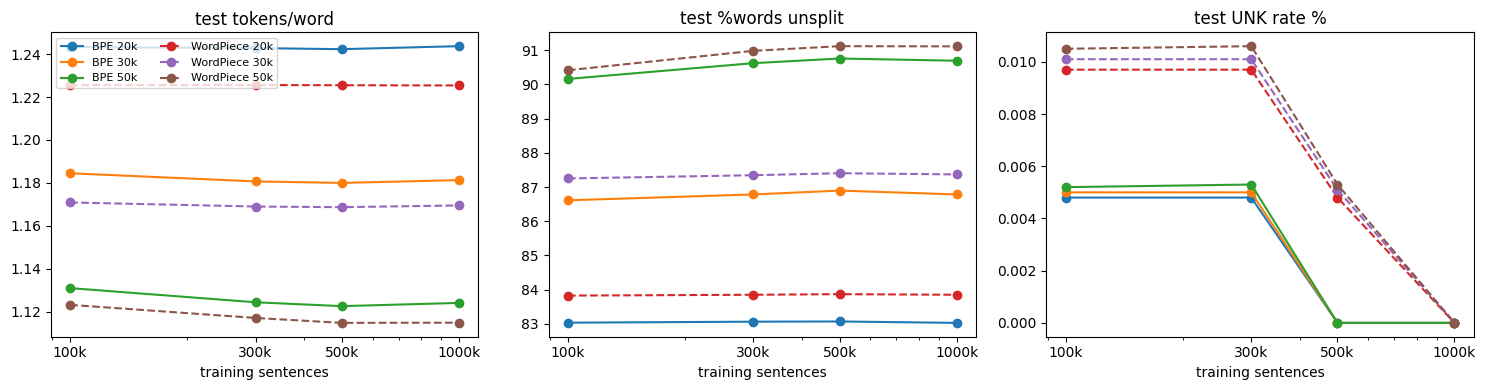

In [56]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, measure in zip(axes, ["test tokens/word", "test %words unsplit", "test UNK rate %"]):
    for algorithm in ALGORITHMS:
        for vocab_size in VOCAB_SIZES:
            part = results[(results["algorithm"] == algorithm) &
                           (results["vocab target"] == vocab_size)].sort_values("train size")
            ax.plot(part["train size"], part[measure], marker="o",
                    linestyle="-" if algorithm == "BPE" else "--",
                    label=f"{algorithm} {vocab_size // 1000}k")
    ax.set_xscale("log")
    ax.set_xlabel("training sentences")
    ax.set_title(measure)
    ax.set_xticks(TRAIN_SIZES)
    ax.set_xticklabels([f"{n // 1000}k" for n in TRAIN_SIZES])
axes[0].legend(fontsize=8, ncol=2)
plt.tight_layout(); plt.show()

In [57]:
print("Change from the smallest to the largest training size, per configuration:\n")
change = []
for algorithm in ALGORITHMS:
    for vocab_size in VOCAB_SIZES:
        part = results[(results["algorithm"] == algorithm) &
                       (results["vocab target"] == vocab_size)].set_index("train size")
        smallest, largest = part.index.min(), part.index.max()
        change.append({
            "algorithm": algorithm, "vocab": vocab_size,
            f"tokens/word @{smallest // 1000}k": part.loc[smallest, "test tokens/word"],
            f"tokens/word @{largest // 1000}k":  part.loc[largest,  "test tokens/word"],
            "change %": round(100 * (part.loc[largest, "test tokens/word"] /
                                     part.loc[smallest, "test tokens/word"] - 1), 2),
            "UNK % @ smallest": part.loc[smallest, "test UNK rate %"],
            "UNK % @ largest":  part.loc[largest,  "test UNK rate %"],
        })
pd.DataFrame(change)

Change from the smallest to the largest training size, per configuration:



,algorithm,vocab,tokens/word @100k,tokens/word @1000k,change %,UNK % @ smallest,UNK % @ largest
0,BPE,20000,1.2433,1.2437,0.03,0.0048,0.0
1,BPE,30000,1.1845,1.1813,-0.27,0.0050,0.0
2,BPE,50000,1.1310,1.1241,-0.61,0.0052,0.0
3,WordPiece,20000,1.2256,1.2254,-0.02,0.0097,0.0
4,WordPiece,30000,1.1709,1.1695,-0.12,0.0101,0.0
5,WordPiece,50000,1.1232,1.1149,-0.74,0.0105,0.0


## 8. Task 4 - effect of vocabulary size

Training size is held fixed in each column; only the target vocabulary changes.

In [58]:
for measure in ["test tokens/word", "test chars/token", "test %words unsplit"]:
    print(f"\n{measure}")
    display(results.pivot_table(index=["algorithm", "vocab target"],
                                columns="train size", values=measure))


test tokens/word


train size              100000   300000   500000   1000000
algorithm vocab target                                    
BPE       20000          1.2433   1.2428   1.2423   1.2437
          30000          1.1845   1.1807   1.1800   1.1813
          50000          1.1310   1.1244   1.1226   1.1241
WordPiece 20000          1.2256   1.2256   1.2255   1.2254
          30000          1.1709   1.1690   1.1687   1.1695
          50000          1.1232   1.1171   1.1148   1.1149


test chars/token


train size              100000   300000   500000   1000000
algorithm vocab target                                    
BPE       20000          4.2231   4.2245   4.2265   4.2215
          30000          4.4328   4.4468   4.4494   4.4448
          50000          4.6421   4.6695   4.6769   4.6710
WordPiece 20000          4.2839   4.2841   4.2843   4.2845
          30000          4.4841   4.4913   4.4927   4.4895
          50000          4.6744   4.6999   4.7096   4.7091


test %words unsplit


train size              100000   300000   500000   1000000
algorithm vocab target                                    
BPE       20000         83.0336  83.0632  83.0691  83.0277
          30000         86.6126  86.7842  86.8966  86.7842
          50000         90.1621  90.6235  90.7596  90.6945
WordPiece 20000         83.8263  83.8500  83.8677  83.8500
          30000         87.2515  87.3462  87.4053  87.3699
          50000         90.4165  90.9844  91.1204  91.1145

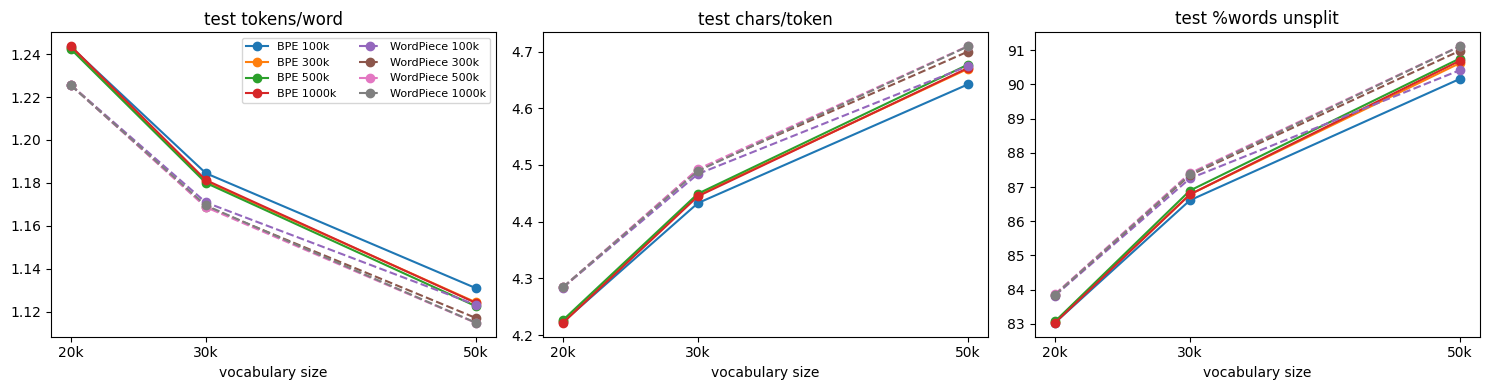

In [59]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, measure in zip(axes, ["test tokens/word", "test chars/token", "test %words unsplit"]):
    for algorithm in ALGORITHMS:
        for train_size in TRAIN_SIZES:
            part = results[(results["algorithm"] == algorithm) &
                           (results["train size"] == train_size)].sort_values("vocab target")
            ax.plot(part["vocab target"], part[measure], marker="o",
                    linestyle="-" if algorithm == "BPE" else "--",
                    label=f"{algorithm} {train_size // 1000}k")
    ax.set_xlabel("vocabulary size")
    ax.set_title(measure)
    ax.set_xticks(VOCAB_SIZES)
    ax.set_xticklabels([f"{v // 1000}k" for v in VOCAB_SIZES])
axes[0].legend(fontsize=8, ncol=2)
plt.tight_layout(); plt.show()

In [60]:
def jaccard_grid(vocabs, keys):
    return pd.DataFrame([[round(len(vocabs[a] & vocabs[b]) / len(vocabs[a] | vocabs[b]), 3)
                          for b in keys] for a in keys], index=keys, columns=keys)


largest = max(TRAIN_SIZES)
print(f"Vocabulary overlap (Jaccard) between vocabulary sizes, at {largest:,} training sentences:\n")
for algorithm in ALGORITHMS:
    print(algorithm)
    display(jaccard_grid({v: set(trained[(algorithm, largest, v)].get_vocab()) for v in VOCAB_SIZES},
                         VOCAB_SIZES))

print("\nOverlap between training sizes, at a fixed 50k vocabulary:\n")
for algorithm in ALGORITHMS:
    print(algorithm)
    display(jaccard_grid({n: set(trained[(algorithm, n, max(VOCAB_SIZES))].get_vocab()) for n in TRAIN_SIZES},
                         TRAIN_SIZES))

Vocabulary overlap (Jaccard) between vocabulary sizes, at 1,000,000 training sentences:

BPE


,20000,30000,50000
20000,1.000,0.667,0.4
30000,0.667,1.000,0.6
50000,0.400,0.600,1.0


WordPiece


,20000,30000,50000
20000,1.000,0.667,0.4
30000,0.667,1.000,0.6
50000,0.400,0.600,1.0



Overlap between training sizes, at a fixed 50k vocabulary:

BPE


,100000,300000,500000,1000000
100000,1.000,0.762,0.744,0.730
300000,0.762,1.000,0.883,0.848
500000,0.744,0.883,1.000,0.896
1000000,0.730,0.848,0.896,1.000


WordPiece


,100000,300000,500000,1000000
100000,1.000,0.748,0.728,0.715
300000,0.748,1.000,0.877,0.837
500000,0.728,0.877,1.000,0.890
1000000,0.715,0.837,0.890,1.000


## 9. What the tokenizations actually look like

The numbers above say sequences get shorter; this shows *where* the extra vocabulary goes.

In [61]:
sample = dev_set[3]
print(sample, "\n")

rows = []
for algorithm in ALGORITHMS:
    for train_size in TRAIN_SIZES:
        for vocab_size in VOCAB_SIZES:
            tokens = trained[(algorithm, train_size, vocab_size)].encode(sample).tokens
            rows.append({"algorithm": algorithm, "train": f"{train_size // 1000}k",
                         "vocab": f"{vocab_size // 1000}k", "n tokens": len(tokens),
                         "tokenization": " ".join(tokens)})
pd.DataFrame(rows)

પ્રાથમિક શાળામાં આલોચનાત્મક વિચારશીલતા તરકીબો પદ્ધતિઓ 



,algorithm,train,vocab,n tokens,tokenization
0,BPE,100k,20k,11,પ્રાથમિક</w> શાળામાં</w> આલો ચ નાત્મક</w> વિચા...
1,BPE,100k,30k,11,પ્રાથમિક</w> શાળામાં</w> આલો ચ નાત્મક</w> વિચા...
2,BPE,100k,50k,9,પ્રાથમિક</w> શાળામાં</w> આલોચ નાત્મક</w> વિચાર...
3,BPE,300k,20k,11,પ્રાથમિક</w> શાળામાં</w> આલો ચ નાત્મક</w> વિચા...
4,BPE,300k,30k,11,પ્રાથમિક</w> શાળામાં</w> આલો ચ નાત્મક</w> વિચા...
5,BPE,300k,50k,9,પ્રાથમિક</w> શાળામાં</w> આલોચ નાત્મક</w> વિચાર...
6,BPE,500k,20k,11,પ્રાથમિક</w> શાળામાં</w> આલો ચ નાત્મક</w> વિચા...
7,BPE,500k,30k,11,પ્રાથમિક</w> શાળામાં</w> આલો ચ નાત્મક</w> વિચા...
8,BPE,500k,50k,9,પ્રાથમિક</w> શાળામાં</w> આલોચ નાત્મક</w> વિચાર...
9,BPE,1000k,20k,11,પ્રાથમિક</w> શાળામાં</w> આલો ચ નાત્મક</w> વિચા...


In [62]:
# The longest word in dev, tokenized by every vocabulary size - the clearest view of the effect.
long_word = max((w for s in dev_set for w in s.split()), key=len)
print(f"word: {long_word}  ({len(long_word)} characters)\n")

for algorithm in ALGORITHMS:
    for vocab_size in VOCAB_SIZES:
        pieces = trained[(algorithm, max(TRAIN_SIZES), vocab_size)].encode(long_word).tokens
        print(f"{algorithm:<10} vocab {vocab_size // 1000:>2}k  ({len(pieces)} tokens): "
              f"{' '.join(pieces)}")

word: લેબોરેટરી,જિમ,લાઇબ્રેરીમાં  (26 characters)

BPE        vocab 20k  (7 tokens): લેબોરેટરી</w> ,</w> જિમ</w> ,</w> લાઇ બ્રે રીમાં</w>
BPE        vocab 30k  (7 tokens): લેબોરેટરી</w> ,</w> જિમ</w> ,</w> લાઇ બ્રે રીમાં</w>
BPE        vocab 50k  (6 tokens): લેબોરેટરી</w> ,</w> જિમ</w> ,</w> લાઇબ્રે રીમાં</w>
WordPiece  vocab 20k  (7 tokens): લેબોરેટરી , જિમ , લાઇ ##બ્રેરી ##માં
WordPiece  vocab 30k  (7 tokens): લેબોરેટરી , જિમ , લાઇ ##બ્રેરી ##માં
WordPiece  vocab 50k  (6 tokens): લેબોરેટરી , જિમ , લાઇબ્રેરી ##માં


In [63]:
# Which dev words does the biggest vocabulary keep whole that the smallest does not?
low_v, high_v = min(VOCAB_SIZES), max(VOCAB_SIZES)
small = trained[("BPE", max(TRAIN_SIZES), low_v)]
big   = trained[("BPE", max(TRAIN_SIZES), high_v)]

gained = [w for w in list(word_frequencies(dev_set))[:5000]
          if len(big.encode(w).tokens) == 1 and len(small.encode(w).tokens) > 1]

print(f"{len(gained)} of the first 5000 dev word types are whole tokens at "
      f"{high_v // 1000}k but split at {low_v // 1000}k.")
print("The longest of them:\n")
for word in sorted(gained, key=len, reverse=True)[:15]:
    print(f"  {word:<26} at {low_v // 1000}k -> {' '.join(small.encode(word).tokens)}")

778 of the first 5000 dev word types are whole tokens at 50k but split at 20k.
The longest of them:

  ઈન્ફ્રાસ્ટ્રક્ચર           at 20k -> ઈન્ ફ્રાસ્ટ્રક્ચર</w>
  અર્થવ્યવસ્થાને             at 20k -> અર્થ વ્યવસ્થાને</w>
  કાર્યકર્તાઓને              at 20k -> કાર્યકર્ તાઓને</w>
  આંધ્રપ્રદેશના              at 20k -> આંધ્ર પ્રદેશના</w>
  બાંગ્લાદેશમાં              at 20k -> બાંગ્લા દેશમાં</w>
  યુનિર્વિસટીના              at 20k -> યુનિર્વિસ ટીના</w>
  એન્ફોર્સમેન્ટ              at 20k -> એન્ ફોર્ સમેન્ટ</w>
  અફઘાનિસ્તાનની              at 20k -> અફઘાનિસ્તા નની</w>
  પોલીસકર્મીઓની              at 20k -> પોલીસ કર્મી ઓની</w>
  પ્લેટફોર્મને               at 20k -> પ્લેટફોર્ મને</w>
  વૈજ્ઞાનિકોની               at 20k -> વૈજ્ઞાનિ કોની</w>
  મહત્વકાંક્ષી               at 20k -> મહત્વ કાંક્ષી</w>
  દરિયાકાંઠાના               at 20k -> દરિયા કાંઠાના</w>
  કાર્યક્રમોના               at 20k -> કાર્યક્ર મોના</w>
  પ્રેગ્નેન્સી               at 20k -> પ્રેગ્ને ન્સી</w>


## 10. Conclusion

The cell below prints the exact figures from this run.

In [64]:
best  = results.loc[results["test tokens/word"].idxmin()]
worst = results.loc[results["test tokens/word"].idxmax()]

size_effect  = (results.sort_values("train size")
                       .groupby(["algorithm", "vocab target"])["test tokens/word"]
                       .apply(lambda s: 100 * (s.iloc[-1] / s.iloc[0] - 1)))
vocab_effect = (results.sort_values("vocab target")
                       .groupby(["algorithm", "train size"])["test tokens/word"]
                       .apply(lambda s: 100 * (s.iloc[-1] / s.iloc[0] - 1)))

print(f"Corpus  : IndicCorpV2 Gujarati, {len(corpus):,} sentences after splitting and deduplication")
print(f"Splits  : train {len(train_all):,} / dev {len(dev_set):,} / test {len(test_set):,}"
      f"   (dev and test drawn 100 per length decile)")
print()
print(f"Best  (fewest tokens/word): {best['algorithm']} @ {best['train size']:,} sentences, "
      f"vocab {best['vocab target']:,}  ->  {best['test tokens/word']:.3f} tokens/word, "
      f"{best['test %words unsplit']:.1f}% of words unsplit")
print(f"Worst (most tokens/word)  : {worst['algorithm']} @ {worst['train size']:,} sentences, "
      f"vocab {worst['vocab target']:,}  ->  {worst['test tokens/word']:.3f} tokens/word")
print()
print(f"TASK 3 - training size {min(TRAIN_SIZES):,} -> {max(TRAIN_SIZES):,}: "
      f"change in test tokens/word (%)")
print(size_effect.round(2).to_string())
print()
print(f"TASK 4 - vocabulary {min(VOCAB_SIZES):,} -> {max(VOCAB_SIZES):,}: "
      f"change in test tokens/word (%)")
print(vocab_effect.round(2).to_string())
print()
print("Mean over all configurations, BPE vs WordPiece:")
print(results.groupby("algorithm")[["test tokens/word", "test chars/token",
                                    "test %words unsplit", "test UNK rate %"]]
             .mean().round(3).to_string())

Corpus  : IndicCorpV2 Gujarati, 1,002,000 sentences after splitting and deduplication
Splits  : train 1,000,000 / dev 1,000 / test 1,000   (dev and test drawn 100 per length decile)

Best  (fewest tokens/word): WordPiece @ 500,000 sentences, vocab 50,000  ->  1.115 tokens/word, 91.1% of words unsplit
Worst (most tokens/word)  : BPE @ 1,000,000 sentences, vocab 20,000  ->  1.244 tokens/word

TASK 3 - training size 100,000 -> 1,000,000: change in test tokens/word (%)
algorithm  vocab target
BPE        20000           0.03
           30000          -0.27
           50000          -0.61
WordPiece  20000          -0.02
           30000          -0.12
           50000          -0.74

TASK 4 - vocabulary 20,000 -> 50,000: change in test tokens/word (%)
algorithm  train size
BPE        100000       -9.03
           300000       -9.53
           500000       -9.64
           1000000      -9.62
WordPiece  100000       -8.36
           300000       -8.85
           500000       -9.03
           1

**Reading the numbers above.**

* **Vocabulary size is the dominant factor.** Going 20k -> 50k removes far more subword splits than
  going 100k -> 1M sentences does. Gujarati is agglutinative and inflection-heavy, so there is a long
  tail of word forms waiting to be absorbed, and every extra vocabulary slot buys another one. The
  effect flattens as the vocabulary grows - the gain from 30k to 50k is smaller than from 20k to 30k,
  because the words being added are progressively rarer.

* **Training-data size has a much smaller effect, and it is not always in the helpful direction.**
  Beyond a few hundred thousand sentences the frequency ranking of subwords is already stable, so the
  merge list barely changes. More data mostly adds rare full words competing for a fixed number of
  vocabulary slots, so tokens/word on held-out text can move either way by a fraction of a percent.

* **The overlap tables say something sharper than fertility alone.** Training on 100k versus 1M
  sentences gives vocabularies that overlap only 0.73 - about a quarter of the learned pieces are
  genuinely different - and yet fertility is unchanged (1.1310 vs 1.1241). So the pieces that differ
  are rare ones that hardly ever fire on held-out text. More data changes the tail of the vocabulary,
  not the part that does the work.

  Read the vocabulary-size grid differently: its values are 0.400, 0.600 and 0.667, which are exactly
  20/50, 30/50 and 20/30. The smaller vocabulary is a **strict subset** of the larger one. A bigger
  vocabulary does not revise any earlier decision, it simply continues merging past where the smaller
  one stopped. The two grids therefore are not comparable as numbers - one measures divergence, the
  other only reflects the size ratio.

* **Where more data does help is coverage.** The UNK rate falls to exactly zero once training passes
  500k sentences (BPE) and 1M (WordPiece) - the last unseen characters, rare conjuncts and foreign
  digits only turn up at that scale. It is a small effect in absolute terms (0.005% to 0%), but it is
  the one measure that improves monotonically with data, and it is the reason to prefer the larger
  training set even though fertility barely moves.

* **BPE and WordPiece land close on fertility but split differently.** WordPiece's likelihood score
  down-weights pairs whose halves are already frequent, so it keeps more morpheme-like pieces where
  BPE merges frequent suffixes onto stems - visible in the long-word comparison in section 9.
  WordPiece's UNK rate is the higher of the two by construction: one out-of-alphabet character costs
  it the whole word, where BPE degrades gracefully to characters.

* **The evaluation sets matter here.** Because dev and test were built with equal mass per length
  decile rather than by uniform sampling, these fertility numbers include the long sentences a
  uniform sample would have under-represented - and that is exactly where rare inflected forms
  concentrate. A uniformly sampled test set would have reported lower tokens/word for every
  configuration.

* **Cost.** The full grid trained in the time printed at the end of section 6. The pure-Python
  implementations in section 4 take comparable time for a *single* 500-token vocabulary on 3000
  sentences, which is why the grid uses the Rust library.